# Home Credit: данные и признаки

В исходном проекте уже были агрегаты кредитной истории. Я сохранил их и перенёс расчёт в `src/credit_scoring/features.py`. Здесь посмотрю, что получилось после объединения таблиц: сохранились ли клиенты, где не хватает истории и какие признаки чаще пропущены.

Признаки рассчитаны командой `PYTHONPATH=src python -m credit_scoring.prepare --data-dir data` из корня проекта. Источник — [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk/data).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports/portfolio"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})


In [2]:
quality = json.loads((REPORTS / "data_quality.json").read_text())
pd.Series(quality, name="value").to_frame()

,value
rows_before_join,307511.000000
rows_after_join,307511.000000
duplicate_client_ids,0.000000
missing_target,0.000000
default_rate,0.080729
infinite_values,0.000000
employment_placeholder_count,55374.000000
zero_income,0.000000


После объединения осталось 307 511 клиентов; повторов идентификаторов и пропусков в TARGET нет. Значение 365243 в стаже встречается у 55 374 клиентов: это специальное значение, поэтому перед расчётом отношения стажа к возрасту заменяю его на NaN. Отсутствующую историю не заполняю нулями целиком: нулевая просрочка и отсутствие записей в бюро означают разные вещи.

In [3]:
pd.read_csv(REPORTS / "source_quality.csv")

,table,rows,columns,missing_cells,clients
0,bureau,1716428,17,3939947,305811.0
1,bureau_balance,27299925,3,0,NaN
2,POS_CASH_balance,10001358,8,52158,337252.0
3,installments_payments,13605401,8,5810,339587.0
4,credit_card_balance,3840312,23,5877356,103558.0
5,previous_application,1670214,37,11109336,338857.0
6,application_train,307511,122,9152465,307511.0


## Какие признаки добавлены

Из bureau беру число кредитов, долг и просрочки. Для POS и кредитных карт сначала собираю историю каждого договора, затем агрегирую её до клиента. В installments несколько строк могут относиться к одному платежу: сначала складываю части платежа, потом считаю задержку и недоплату. В previous_application использую суммы, доли одобрений и отказы.

Объединение идёт по SK_ID_CURR после агрегации. Так одна заявка остаётся одной строкой, даже если у клиента много платежей.

In [4]:
groups = json.loads((REPORTS / "feature_groups.json").read_text())
pd.Series({name: len(columns) for name, columns in groups.items()}, name="features").to_frame()

,features
application,125
application_bureau,141
all_history,226


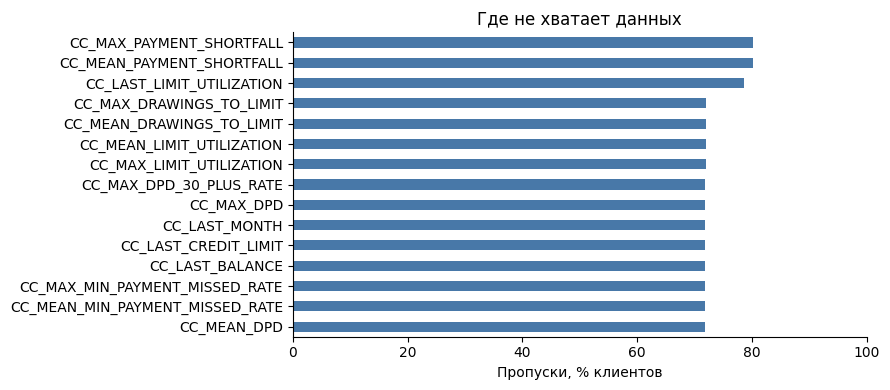

In [5]:
missing = pd.read_csv(REPORTS / "feature_missingness.csv", index_col=0).iloc[:15]
ax = missing.iloc[::-1, 0].mul(100).plot.barh(color="#4878a8")
ax.set(xlabel="Пропуски, % клиентов", ylabel="", title="Где не хватает данных")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

У признаков кредитных карт много пропусков: такая история есть не у каждого клиента. Поэтому добавлены отдельные HAS_*_HISTORY. Для линейной модели числовые пропуски заполняются медианой внутри каждого обучающего фолда; CatBoost получает NaN в числах и отдельное значение Missing в категориях. Полезность этих групп проверяю в следующем ноутбуке.